In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування стилю графіків
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 6]

# Завантаження датасету
df_entrant = pd.read_excel('Зараховані на навчання_2025_(013) _03.11.2026 13-20.xlsx.xlsx')

In [2]:
df_entrant.info()

<class 'pandas.DataFrame'>
RangeIndex: 4834 entries, 0 to 4833
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Рік вступу             4834 non-null   int64  
 1   Освітній ступінь       4834 non-null   str    
 2   Основа вступу          4834 non-null   str    
 3   Код спеціальності      4834 non-null   str    
 4   Назва спеціальності    4834 non-null   str    
 5   Спеціалізація          1529 non-null   str    
 6   Регіон                 4831 non-null   str    
 7   Код                    4834 non-null   int64  
 8   Назва закладу освіти   4834 non-null   str    
 9   Код головного закладу  267 non-null    float64
 10  Форма власності        4834 non-null   str    
 11  Підпорядкування        4203 non-null   str    
 12  Денна (бюджет)         4834 non-null   int64  
 13  Денна (контракт)       4834 non-null   int64  
 14  Заочна (бюджет)        4834 non-null   int64  
 15  Заочна (контрак

In [3]:
df_entrant.head()

,Рік вступу,Освітній ступінь,Основа вступу,Код спеціальності,Назва спеціальності,Спеціалізація,Регіон,Код,Назва закладу освіти,Код головного закладу,Форма власності,Підпорядкування,Денна (бюджет),Денна (контракт),Заочна (бюджет),Заочна (контракт),Вечірня (бюджет),Вечірня (контракт)
0,2025,Бакалавр,Повна загальна середня освіта,013,Початкова освіта,NaN,Львівська область,282,Львівський національний університет імені Іван...,NaN,Державна,Міністерство освіти і науки України,0,0,0,1,0,0
1,2025,Бакалавр,Повна загальна середня освіта,022,Дизайн,022.03 Дизайн середовища,Львівська область,253,Львівська національна академія мистецтв,NaN,Державна,Міністерство культури України,0,1,0,0,0,0
2,2025,Бакалавр,Повна загальна середня освіта,053,Психологія,NaN,Львівська область,282,Львівський національний університет імені Іван...,NaN,Державна,Міністерство освіти і науки України,0,1,0,0,0,0
3,2025,Бакалавр,Повна загальна середня освіта,106,Географія,NaN,Львівська область,282,Львівський національний університет імені Іван...,NaN,Державна,Міністерство освіти і науки України,1,0,0,0,0,0
4,2025,Бакалавр,Повна загальна середня освіта,262,Правоохоронна діяльність,NaN,Чернігівська область,850,Пенітенціарна академія України,NaN,Державна,Міністерство юстиції України,0,0,0,1,0,0


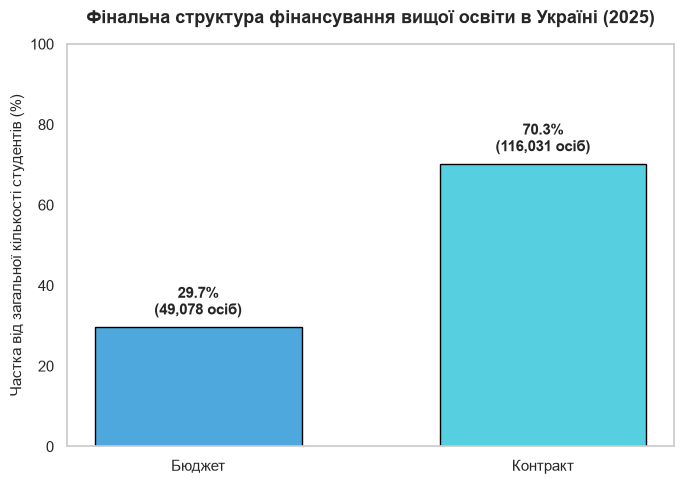

Кількість аналізованих рядків (пропозицій ЗВО): 4834
Загальна кількість зарахованих студентів в Україні: 165,109 осіб


In [4]:
# Рахуємо загальну кількість студентів у системі
total_students = df_entrant[['Денна (бюджет)', 'Денна (контракт)', 
                             'Заочна (бюджет)', 'Заочна (контракт)', 
                             'Вечірня (бюджет)', 'Вечірня (контракт)']].sum().sum()

# Агрегуємо суми для бюджету та контракту по усім формам
total_budget = df_entrant[['Денна (бюджет)', 'Заочна (бюджет)', 'Вечірня (бюджет)']].sum().sum()
total_contract = df_entrant[['Денна (контракт)', 'Заочна (контракт)', 'Вечірня (контракт)']].sum().sum()

funding_summary = pd.Series({'Бюджет': total_budget, 'Контракт': total_contract})
funding_pct = (funding_summary / total_students) * 100

# Будуємо графік фінансування
plt.figure(figsize=(7, 5))
colors = ['#4EA8DE', '#56CFE1'] 
plt.bar(funding_pct.index, funding_pct.values, color=colors, edgecolor='black', width=0.6)

plt.title('Фінальна структура фінансування вищої освіти в Україні (2025)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Частка від загальної кількості студентів (%)', fontsize=11)
plt.ylim(0, 100)
plt.grid(False)

# Додаємо підписи відсотків та кількості людей прямо на чистий фон
for i, (val, people) in enumerate(zip(funding_pct.values, funding_summary.values)):
    plt.text(i, val + 2, f"{val:.1f}%\n({int(people):,} осіб)", ha='center', va='bottom', fontsize=11, fontweight='bold')

# Оптимізація розташування елементів та збереження графіка високої якості для документації
plt.tight_layout()
plt.savefig('final_funding_structure.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Кількість аналізованих рядків (пропозицій ЗВО): {len(df_entrant)}")
print(f"Загальна кількість зарахованих студентів в Україні: {total_students:,} осіб")



--- РОЗПОДІЛ ФОРМ НАВЧАННЯ ---
Денна форма: 135,471 осіб
Заочна forma: 29,617 осіб
Вечірня форма: 21 осіб


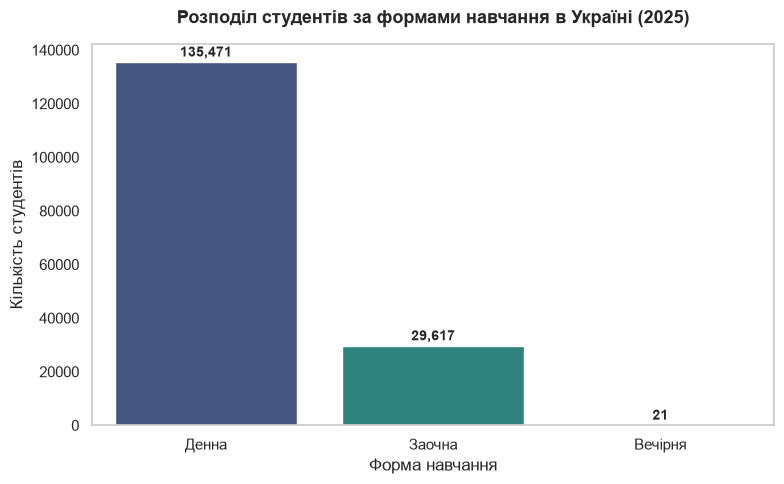

In [5]:
# Розрахунок загальної кількісті студентів для трьох форм навчання
total_day = df_entrant[["Денна (бюджет)", "Денна (контракт)"]].sum().sum()
total_extramural = (
    df_entrant[["Заочна (бюджет)", "Заочна (контракт)"]].sum().sum()
)
total_evening = (
    df_entrant[["Вечірня (бюджет)", "Вечірня (контракт)"]].sum().sum()
)

print("--- РОЗПОДІЛ ФОРМ НАВЧАННЯ ---")
print(f"Денна форма: {int(total_day):,} осіб")
print(f"Заочна forma: {int(total_extramural):,} осіб")
print(f"Вечірня форма: {int(total_evening):,} осіб")

# Побудова Bar Chart для візуального порівняння форм навчання
forms = ["Денна", "Заочна", "Вечірня"]
counts = [total_day, total_extramural, total_evening]

plt.figure(figsize=(8, 5))
sns.barplot(x=forms, y=counts, hue=forms, palette="viridis", legend=False)
plt.title(
    "Розподіл студентів за формами навчання в Україні (2025)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Кількість студентів")
plt.xlabel("Форма навчання")
plt.grid(False)

# Підписи значень над стовпчиками
for i, count in enumerate(counts):
    plt.text(
        i,
        count + 1000,
        f"{int(count):,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

# Автоматичне вирівнювання елементів та збереження графіка високої якості для GitHub
plt.tight_layout()
plt.savefig("education_forms_distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [6]:
# Поглиблений аналіз та локалізація закладів освіти за вечірньою формою навчання
df_entrant['Вечірня (разом)'] = df_entrant['Вечірня (бюджет)'] + df_entrant['Вечірня (контракт)']
evening_active = df_entrant[df_entrant['Вечірня (разом)'] > 0]

print("--- ДЕТАЛЬНЕ РОЗСЛІДУВАННЯ ВЕЧІРНЬОЇ ФОРМИ НАВЧАННЯ ---")
evening_summary = evening_active.groupby(['Регіон', 'Назва спеціальності'])['Вечірня (разом)'].sum().reset_index(name='Кількість студентів')

print(evening_summary.sort_values(by='Кількість студентів', ascending=False).to_string(index=False))

# Перевірка структури фінансування для вечірньої форми
print(f"\nБюджетних місць на вечірній формі: {int(evening_active['Вечірня (бюджет)'].sum())}")
print(f"Контрактних місць на вечірній формі: {int(evening_active['Вечірня (контракт)'].sum())}")

--- ДЕТАЛЬНЕ РОЗСЛІДУВАННЯ ВЕЧІРНЬОЇ ФОРМИ НАВЧАННЯ ---
              Регіон           Назва спеціальності  Кількість студентів
                Київ Архітектура та містобудування                    7
                Київ                    Психологія                    7
Миколаївська область           Громадське здоров'я                    3
Миколаївська область                Медсестринство                    2
                Київ Біотехнології та біоінженерія                    1
                Київ                    Менеджмент                    1

Бюджетних місць на вечірній формі: 0
Контрактних місць на вечірній формі: 21


Точна кількість регіонів у вашому датасеті: 24



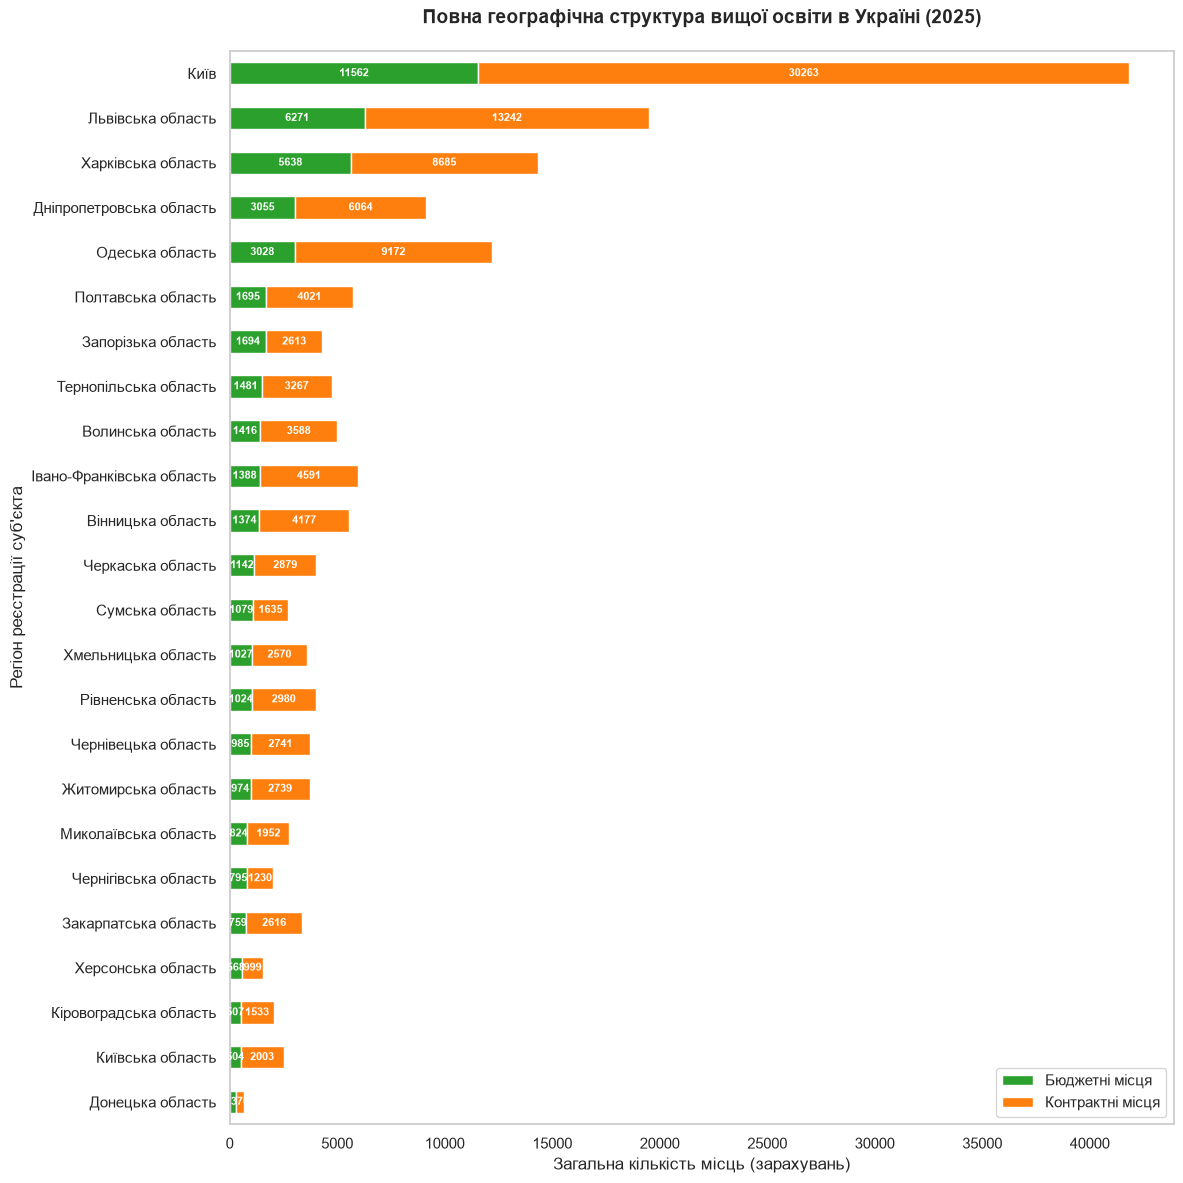

In [7]:
# Розрахунок сумарних показників зарахованих на бюджет та контракт за всіма формами навчання
df_entrant["Разом Бюджет"] = df_entrant[
    ["Денна (бюджет)", "Заочна (бюджет)", "Вечірня (бюджет)"]
].sum(axis=1)
df_entrant["Разом Контракт"] = df_entrant[
    ["Денна (контракт)", "Заочна (контракт)", "Вечірня (контракт)"]
].sum(axis=1)

# Агрегація обсягів набору за регіональною ознакою
all_regions = df_entrant.groupby("Регіон")[
    ["Разом Бюджет", "Разом Контракт"]
].sum()

# Сортування регіонів за спаданням загальної кількості місць
all_regions_sorted = all_regions.sort_values(
    by=["Разом Бюджет", "Разом Контракт"], ascending=False
)

print(f"Точна кількість регіонів у вашому датасеті: {len(all_regions_sorted)}\n")

# Налаштування графічного полотна для регіонального розподілу
fig, ax = plt.subplots(figsize=(12, 12))
all_regions_sorted[["Разом Бюджет", "Разом Контракт"]].plot(
    kind="barh", stacked=True, ax=ax, color=["#2ca02c", "#ff7f0e"]
)

# Відображення числових значень усередині стовпчиків із фільтрацією мінімального порогу видимості
for container in ax.containers:
    ax.bar_label(
        container,
        fmt=lambda x: f"{int(x)}" if x > 300 else "",
        label_type="center",
        color="white",
        weight="bold",
        fontsize=8,
    )

# Оформлення та фіналізація елементів діаграми
plt.title(
    "Повна географічна структура вищої освіти в Україні (2025)",
    fontsize=14,
    pad=20,
    weight="bold",
)
plt.xlabel("Загальна кількість місць (зарахувань)", fontsize=12)
plt.ylabel("Регіон реєстрації суб'єкта", fontsize=12)
plt.gca().invert_yaxis()  # Розміщення найбільших регіонів у верхній частині графіка
plt.legend(
    ["Бюджетні місця", "Контрактні місця"], loc="lower right", fontsize=11
)
plt.grid(False)
# Оптимізація розташування елементів та збереження графіка високої якості для документації
plt.tight_layout()
plt.savefig("regional_education_structure.png", dpi=300, bbox_inches="tight")
plt.show()


In [8]:
# 1. Створення фінальної колонки 'Кількість зарахованих', сумуючи всі форми навчання
df_entrant['Кількість зарахованих'] = df_entrant['Разом Бюджет'] + df_entrant['Разом Контракт']

# 2. Агрегування даних за регіонами
region_table = df_entrant.groupby('Регіон').agg(
    Заклади=('Назва закладу освіти', 'nunique'),
    Бюджет=('Разом Бюджет', 'sum'),
    Контракт=('Разом Контракт', 'sum'),
    Загалом=('Кількість зарахованих', 'sum')
)

# 3. Розрахунок відсотка бюджету та рівня концентрації студентів (середнє на 1 ЗВО)
region_table['Бюджет, %'] = (region_table['Бюджет'] / region_table['Загалом'] * 100).round(1)
region_table['Рівень концентрації студентів'] = (region_table['Загалом'] / region_table['Заклади']).round(1)

# Сортування від найбільшого до найменшого за загальною кількістю студентів
compact_table = region_table.sort_values(by='Загалом', ascending=False)

# 4. Стилізування таблиці 
styled_table = compact_table.style.background_gradient(
    cmap='YlGnBu',       
    subset=['Заклади', 'Бюджет', 'Контракт', 'Загалом', 'Рівень концентрації студентів']
).background_gradient(
    cmap='RdYlGn',       
    subset=['Бюджет, %']
).format({
    'Бюджет': '{:,}',    
    'Контракт': '{:,}',
    'Загалом': '{:,}',
    'Бюджет, %': '{:.1f}%',
    'Рівень концентрації студентів': '{:.1f}'
})

# Збереження стилізованої таблиці регіонів в HTML-файл для документації GitHub
with open('regional_distribution_table.html', 'w', encoding='utf-8') as f:
    f.write(styled_table.to_html())

# Виведення готової кольорової таблиці на екран у Jupyter
styled_table


,Заклади,Бюджет,Контракт,Загалом,"Бюджет, %",Рівень концентрації студентів
Регіон,,,,,,
Київ,74,"11,562","30,263","41,825",27.6%,565.2
Львівська область,22,"6,271","13,242","19,513",32.1%,887.0
Харківська область,26,"5,638","8,685","14,323",39.4%,550.9
Одеська область,22,"3,028","9,172","12,200",24.8%,554.5
Дніпропетровська область,27,"3,055","6,064","9,119",33.5%,337.7
Івано-Франківська область,10,"1,388","4,591","5,979",23.2%,597.9
Полтавська область,13,"1,695","4,021","5,716",29.7%,439.7
Вінницька область,14,"1,374","4,177","5,551",24.8%,396.5
Волинська область,9,"1,416","3,588","5,004",28.3%,556.0


In [9]:
# Фільтрація загального масиву даних за регіональною ознакою (Донецька область)
doneck_df = df_entrant[df_entrant['Регіон'] == 'Донецька область']

# Агрегація даних у розрізі кожного окремого закладу освіти області
doneck_institutions = doneck_df.groupby('Назва закладу освіти').agg(
    Бюджетні_місця=('Разом Бюджет', 'sum'),
    Контрактні_місця=('Разом Контракт', 'sum'),
    Загалом_зараховано=('Кількість зарахованих', 'sum')
)

# Розрахунок відсотка бюджетного фінансування для кожного закладу
doneck_institutions['Відсоток_бюджету'] = (doneck_institutions['Бюджетні_місця'] / doneck_institutions['Загалом_зараховано'] * 100).round(1)

# Сортування закладів від найбільшого обсягу держзамовлення до найменшого
doneck_final_table = doneck_institutions.sort_values(by='Бюджетні_місця', ascending=False)

# Перевірка повноти даних: виведення загальної кількості знайдених закладів в області
print(f"Всього знайдено закладів із бюджетними місцями в області: {len(doneck_final_table)}\n")

# Стилізація фінальної таблиці 
styled_donetsk_full = doneck_final_table.style.background_gradient(
    cmap='Blues',       
    subset=['Бюджетні_місця', 'Контрактні_місця', 'Загалом_зараховано']
).background_gradient(
    cmap='Greens',       
    subset=['Відсоток_бюджету']
).format({
    'Бюджетні_місця': '{:,}',    
    'Контрактні_місця': '{:,}',
    'Загалом_зараховано': '{:,}',
    'Відсоток_бюджету': '{:.1f}%'
})
styled_donetsk_full

Всього знайдено закладів із бюджетними місцями в області: 6



,Бюджетні_місця,Контрактні_місця,Загалом_зараховано,Відсоток_бюджету
Назва закладу освіти,,,,
"Державний вищий навчальний заклад ""Донбаський державний педагогічний університет""",90,120,210,42.9%
"Горлівський інститут іноземних мов Державного вищого навчального закладу ""Донбаський державний педагогічний університет""",65,36,101,64.4%
"Державний вищий навчальний заклад ""Приазовський державний технічний університет""",61,64,125,48.8%
"Державний вищий навчальний заклад ""Донецький національний технічний університет""",36,43,79,45.6%
Донбаська державна машинобудівна академія,25,103,128,19.5%
Бахмутський навчально-науковий професійно-педагогічний інститут Харківського національного університету імені В. Н. Каразіна,11,4,15,73.3%


In [10]:
# Агрегація загальнонаціональних даних у розрізі спеціальностей
national_spec = df_entrant.groupby('Назва спеціальності').agg(
    Бюджет_місць=('Разом Бюджет', 'sum'),
    Контракт_місць=('Разом Контракт', 'sum'),
    Загалом_студентів=('Кількість зарахованих', 'sum')
)

# Розрахунок частки державного замовлення у загальній структурі набору
national_spec['Бюджет, %'] = (national_spec['Бюджет_місць'] / national_spec['Загалом_студентів'] * 100).round(1)

# Формування вибірки ТОП-15 наймасовіших спеціальностей за загальним обсягом зарахованих студентів
national_top15 = national_spec.sort_values(by='Загалом_студентів', ascending=False).head(15)

# Створення та збереження стилізованої таблиці в HTML для документації GitHub
styled_table = national_top15.style.background_gradient(cmap='Purples', subset=['Бюджет_місць', 'Контракт_місць', 'Загалом_студентів']).background_gradient(cmap='RdYlGn', subset=['Бюджет, %']).format({'Бюджет_місць': '{:,.0f}', 'Контракт_місць': '{:,.0f}', 'Загалом_студентів': '{:,.0f}', 'Бюджет, %': '{:.1f}%'})
with open('national_top15_table.html', 'w', encoding='utf-8') as f: f.write(styled_table.to_html())

# Виведення готової таблиці на екран
national_top15.style.background_gradient(
    cmap='Purples', 
    subset=['Бюджет_місць', 'Контракт_місць', 'Загалом_студентів']
).background_gradient(
    cmap='RdYlGn', 
    subset=['Бюджет, %']
).format({
    'Бюджет_місць': '{:,.0f}',
    'Контракт_місць': '{:,.0f}',
    'Загалом_студентів': '{:,.0f}',
    'Бюджет, %': '{:.1f}%'
})
 

,Бюджет_місць,Контракт_місць,Загалом_студентів,"Бюджет, %"
Назва спеціальності,,,,
Менеджмент,686,"14,028","14,714",4.7%
Психологія,986,"10,425","11,411",8.6%
Філологія,"1,979","6,944","8,923",22.2%
Середня освіта,"5,264","2,847","8,111",64.9%
Право,614,"6,964","7,578",8.1%
Маркетинг,299,"6,201","6,500",4.6%
Економіка та міжнародні економічні відносини,557,"5,917","6,474",8.6%
Комп'ютерні науки,"2,681","2,832","5,513",48.6%
"Фінанси, банківська справа, страхування та фондовий ринок",286,"4,327","4,613",6.2%


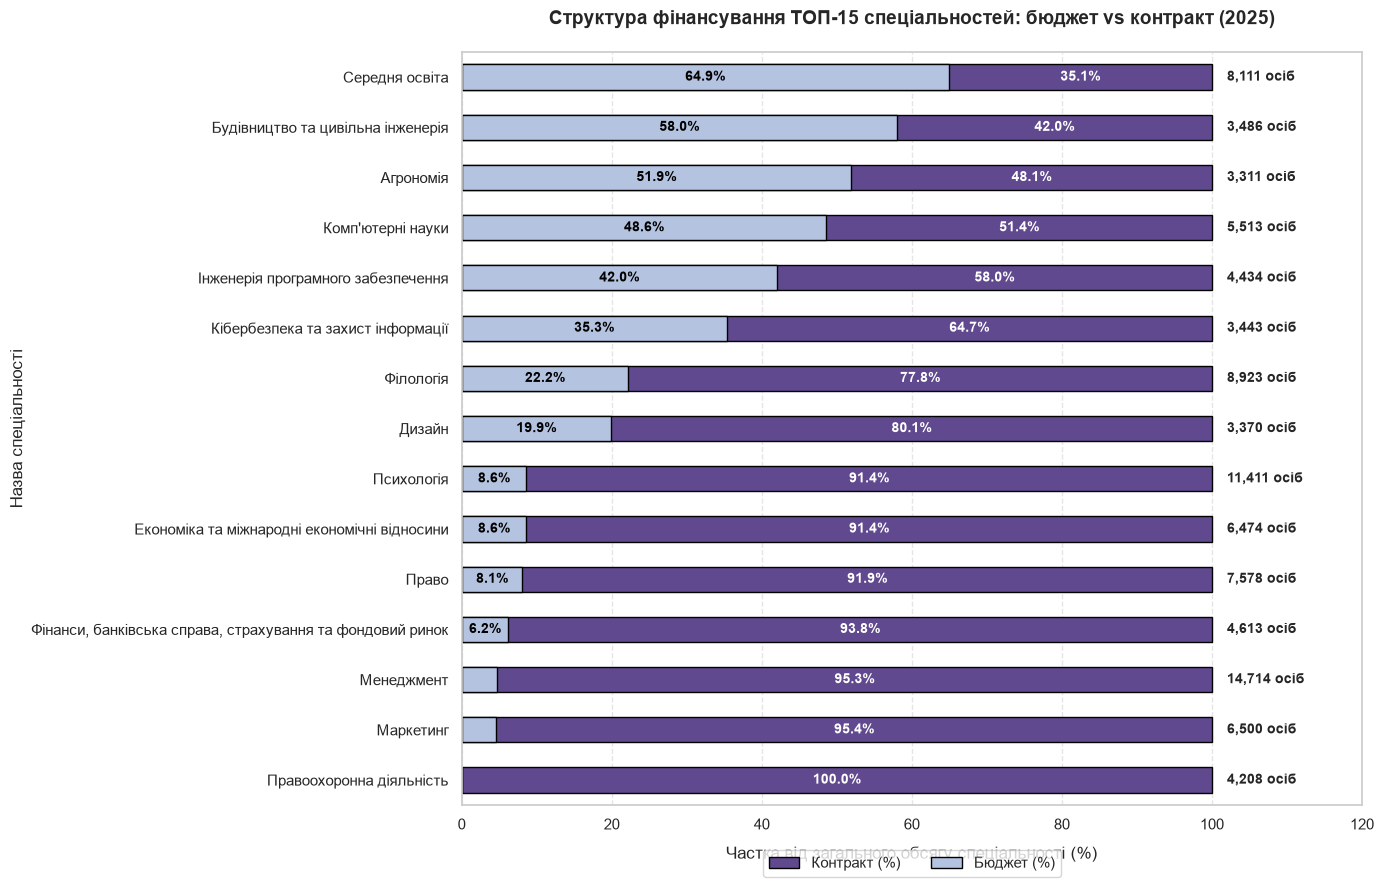

In [12]:
# Сортування спеціальності за відсотком бюджетних місць (від найбільшого до найменшого)
plot_data = national_top15.sort_values(by="Бюджет, %", ascending=False).copy()

# Розрахунок відсотків контрактних місць для балансу (разом має бути 100%)
plot_data["Контракт, %"] = 100 - plot_data["Бюджет, %"]

# Налаштування розміру графіка
plt.figure(figsize=(14, 9))

# Побудова базової 100% лінії для контрактної форми навчання (темно-фіолетовий колір)
sns.barplot(
    x=[100] * len(plot_data),
    y=plot_data.index,
    color="#5c3d99",
    label="Контракт (%)",
    edgecolor="black",
    width=0.5,
)

# Додавання поверх частку бюджетних місць
sns.barplot(
    x=plot_data["Бюджет, %"],
    y=plot_data.index,
    color="#adc1e6",
    label="Бюджет (%)",
    edgecolor="black",
    width=0.5,
)

# Додавання текстових міткок та абсолютних значень всередину стовпчиків
for i, (idx, row) in enumerate(plot_data.iterrows()):
    if row["Бюджет, %"] > 5:
        plt.text(
            row["Бюджет, %"] / 2,
            i,
            f"{row['Бюджет, %']:.1f}%",
            ha="center",
            va="center",
            color="black",
            fontweight="bold",
            fontsize=10,
        )
    plt.text(
        row["Бюджет, %"] + (row["Контракт, %"] / 2),
        i,
        f"{row['Контракт, %']:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=10,
    )
    # Виводимо абсолютну кількість студентів прямо на графік праворуч від стовпчиків
    plt.text(
        102,
        i,
        f"{int(row['Загалом_студентів']):,} осіб",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
    )

# Налаштування назв, підписів осей та легенди графіка
plt.title(
    "Структура фінансування ТОП-15 спеціальностей: бюджет vs контракт (2025)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel(
    "Частка від загального обсягу спеціальності (%)", fontsize=12, labelpad=10
)
plt.ylabel("Назва спеціальності", fontsize=12)
plt.xlim(0, 120)
plt.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2, fontsize=11
)
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Автоматичне вирівнювання елементів та збереження графіка високої якості для GitHub
plt.tight_layout()
plt.savefig("sorted_budget_top15.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
pwd
